# 5. Porównanie: RNN, LSTM, Transformer, RWKV

**Teoria / podsumowanie:** [`05_podsumowanie.md`](05_podsumowanie.md)

Ten notebook niczego nie trenuje: wczytuje wyniki zapisane przez notebooki 00–04 (`results/*.json`)
i rysuje je razem. Uruchom najpierw tamte notebooki.

In [1]:
import math

import matplotlib.pyplot as plt

from common import load_results, plot_memory

plt.rcParams["figure.dpi"] = 110

lm_runs = {name: load_results(name) for name in ("00_bigram", "01_rnn", "02_lstm", "03_transformer", "04_rwkv")}
missing = [name for name, r in lm_runs.items() if r is None]
if missing:
    print("Brakuje wyników z:", missing, "- uruchom odpowiednie notebooki.")
lm_runs = {k: v for k, v in lm_runs.items() if v is not None}

## 1. Modelowanie języka na "Panu Tadeuszu"

Te same dane, ta sama pętla treningowa, 1000 kroków po 32 × 128 znaków. Learning rate dobrany osobno dla
każdego modelu (najlepszy z kilku sprawdzonych).

In [2]:
print(f"{'model':22s} {'parametry':>10s} {'lr':>8s} {'val loss':>9s} {'perplexity':>11s} {'ms/krok':>8s}")
for r in lm_runs.values():
    print(f"{r['name']:22s} {r['n_params']:>10,} {r['config']['lr']:>8.0e} {r['val_loss'][-1]:>9.3f} "
          f"{math.exp(r['val_loss'][-1]):>11.2f} {r['sec_per_step'] * 1000:>8.0f}".replace(",", " "))

model                   parametry       lr  val loss  perplexity  ms/krok
Bigram (bez pamięci)        2 871    1e-02     2.550       12.81        2
RNN                       345 623    4e-03     1.792        6.00       57
LSTM                      526 295    8e-03     1.761        5.82      104
Transformer               832 000    4e-03     1.861        6.43      146
RWKV-4                    880 384    2e-03     1.702        5.49      265


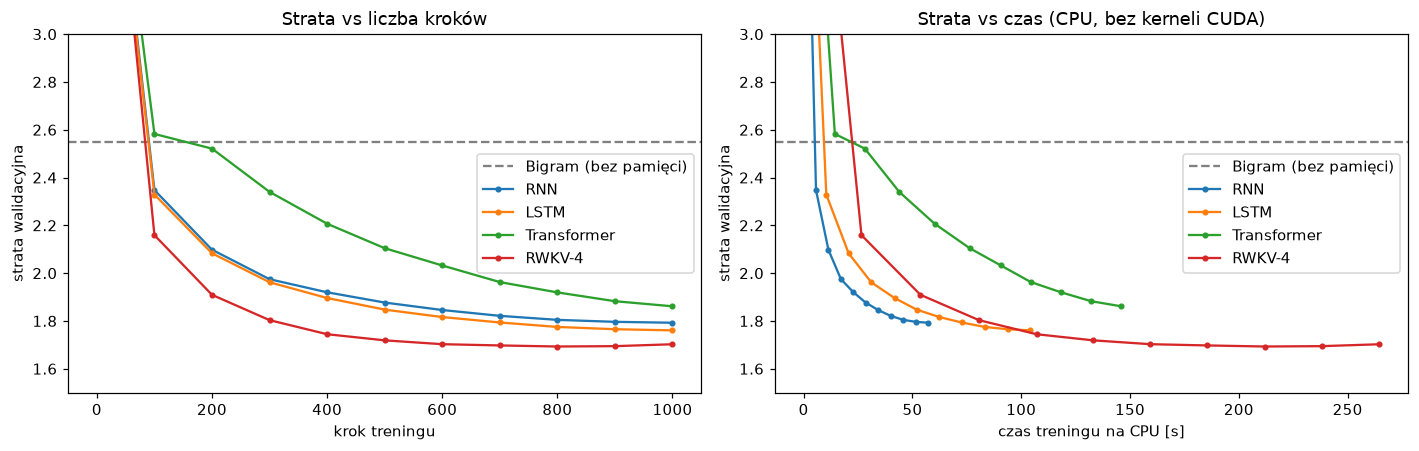

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
for key, r in lm_runs.items():
    if key == "00_bigram":
        for ax in axes:
            ax.axhline(r["val_loss"][-1], color="gray", ls="--", label=r["name"])
        continue
    axes[0].plot(r["eval_step"], r["val_loss"], "o-", ms=3, label=r["name"])
    axes[1].plot(r["eval_time"], r["val_loss"], "o-", ms=3, label=r["name"])
axes[0].set_xlabel("krok treningu")
axes[1].set_xlabel("czas treningu na CPU [s]")
for ax in axes:
    ax.set_ylim(1.5, 3.0)
    ax.set_ylabel("strata walidacyjna")
    ax.legend()
axes[0].set_title("Strata vs liczba kroków")
axes[1].set_title("Strata vs czas (CPU, bez kerneli CUDA)")
plt.tight_layout()
plt.show()

Jak to czytać:

- Wszystkie modele z pamięcią są wyraźnie lepsze od bigramu, więc pamięć działa.
- W tej mikroskali (≤ 0,9 mln parametrów, 4 mln znaków treningu) klasyczne modele lądują blisko siebie,
  a RWKV wychodzi na prowadzenie dzięki token shiftowi i starannej inicjalizacji.
- Prawy wykres jest **specyficzny dla CPU**: na GPU Transformer i RWKV (z kernelem CUDA) trenowałyby się
  o rzędy wielkości szybciej niż RNN/LSTM, bo nie mają pętli po czasie w ciężkich obliczeniach.

## 2. Próbki tekstu (temperatura 0,8)

In [4]:
for key, r in lm_runs.items():
    print(f"=== {r['name']} " + "=" * (60 - len(r["name"])))
    print(r["sample"][:400])
    print()

=== Bigram (bez pamięci) ========================================
Litwo! tyłepoło pię, w szie krogani Sz pie pry wakrórzejewką.
Kro ustesz;
Odo ki te kakrałołośliegłe.
Wochałuko szedzach kraweniej,
Stemokusi sie, prycha ikto gł miu Dle wie ponanopokru,
Po prniedwsposzemie Maznktktrcie,
I sto wstna cię gąchowi stowało powi jedum pasził
Opęc pa go niemcznarawicieży prza pa

=== RNN =========================================================
Litwo! Ojczyzno moja! tym podobadę, lecz widziała, znakiem: przekrót świadkie. Tadeusz spod kamieniu
Na łowę szlachcic podźwiłowiedzi,
Aby w niej, pośpodusz miał przyciszkie głowy; Dróżnie pod Podkomorzego mnie wspomnienie, znowu miał, że wolna na ciężką stare,
U równinami bezpiecznie
On stał i ubrany nad odcieży — prością zwał z drabia, kto jesteś usługiej stronę i drugiem,
Że obwicia się w fiern

=== LSTM ========================================================
Litwo! Ojczyzno moja! to za składę,
Przyszła ogania napierał w woli w jeździa.
To też mu br

## 3. Zadanie pamięciowe: zapamiętaj pierwszy token przez L kroków

RNN                L=5: 100%  L=10:  69%  L=20:  28%  L=40:  13%  L=80:  19%
LSTM (bias f = 1)  L=5: 100%  L=10: 100%  L=20:  68%  L=40:  11%  L=80:  14%
LSTM (bias f = 3)  L=5: 100%  L=10: 100%  L=20: 100%  L=40: 100%  L=80:  14%
Transformer        L=5: 100%  L=10: 100%  L=20: 100%  L=40: 100%  L=80: 100%  L=160: 100%
RWKV-4             L=5: 100%  L=10: 100%  L=20: 100%  L=40: 100%  L=80: 100%  L=160: 100%


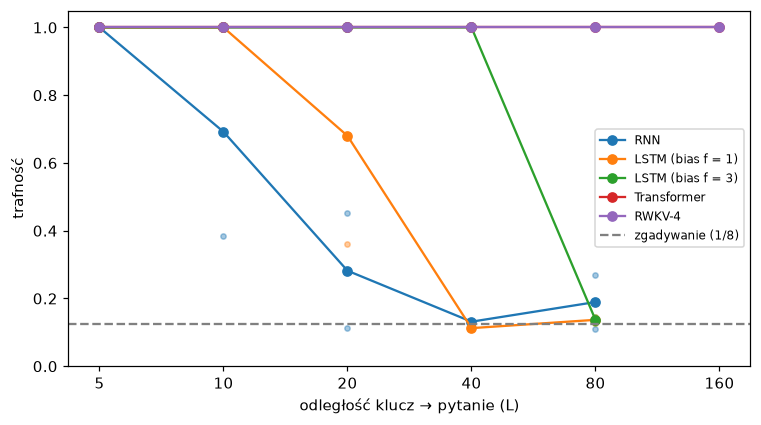

In [5]:
memory_runs = [load_results(n) for n in ("01_rnn_memory", "02_lstm_memory", "02_lstm_memory_fb3",
                                         "03_transformer_memory", "04_rwkv_memory")]
for r in memory_runs:
    if r:
        print(f"{r['name']:18s}", "  ".join(f"L={L}: {a:4.0%}" for L, a in zip(r["lengths"], r["final_acc"])))
plot_memory(memory_runs, plt.subplots(figsize=(8, 4.2))[1])
plt.show()

Modele z rekurencją nieliniową (RNN, LSTM) muszą przenieść informację przez $L$ kroków i uczą się tego coraz
trudniej. Transformer patrzy na klucz bezpośrednio. RWKV też jest RNN-em, ale jego rekurencja jest liniowa,
a WKV to znormalizowana średnia, więc gradient do klucza nie znika z odległością.

## 4. Inferencja: koszt tokenu i pamięć vs długość kontekstu

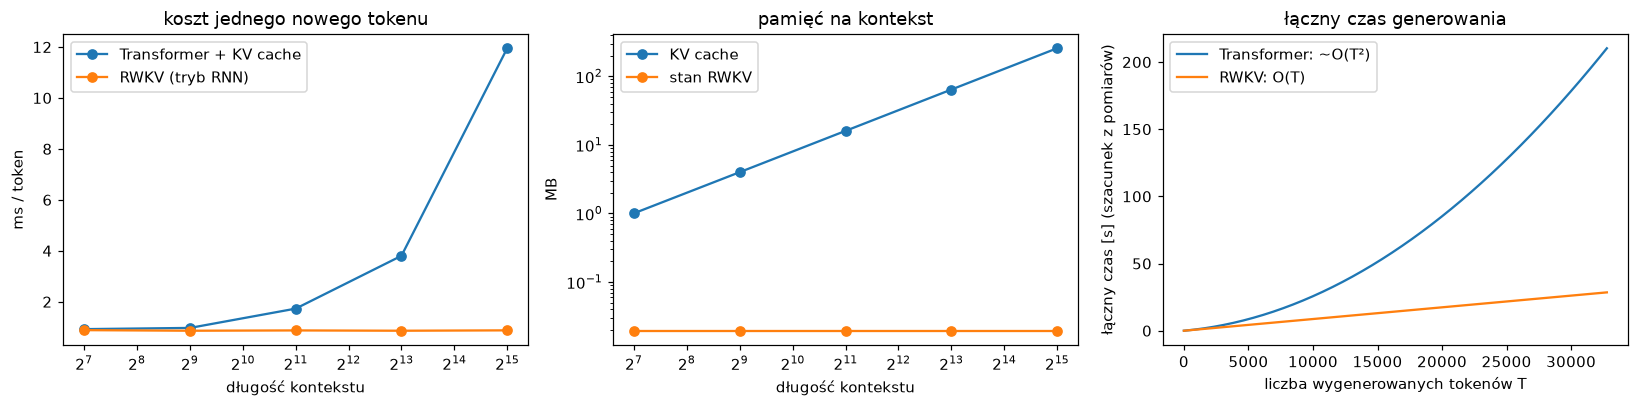

In [6]:
gpt_bench, rwkv_bench = load_results("03_transformer_bench"), load_results("04_rwkv_bench")
if gpt_bench and rwkv_bench:
    fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
    axes[0].plot(gpt_bench["context"], gpt_bench["ms_per_token"], "o-", label="Transformer + KV cache")
    axes[0].plot(rwkv_bench["context"], rwkv_bench["ms_per_token"], "o-", label="RWKV (tryb RNN)")
    axes[0].set_ylabel("ms / token")
    axes[0].set_title("koszt jednego nowego tokenu")
    axes[1].plot(gpt_bench["context"], gpt_bench["cache_MB"], "o-", label="KV cache")
    axes[1].plot(rwkv_bench["context"], rwkv_bench["state_MB"], "o-", label="stan RWKV")
    axes[1].set_yscale("log")
    axes[1].set_ylabel("MB")
    axes[1].set_title("pamięć na kontekst")
    for ax in axes[:2]:
        ax.set_xscale("log", base=2)
        ax.set_xlabel("długość kontekstu")
        ax.legend()

    # koszt tokenu Transformera ≈ base + slope·t (prosta przez pierwszy i ostatni pomiar), więc suma po t = 1..N
    (c0, c1), (m0, m1) = gpt_bench["context"][::len(gpt_bench["context"]) - 1], gpt_bench["ms_per_token"][::len(gpt_bench["context"]) - 1]
    slope = (m1 - m0) / (c1 - c0)
    base = m0 - slope * c0
    rwkv_ms = sum(rwkv_bench["ms_per_token"]) / len(rwkv_bench["ms_per_token"])
    Ns = list(range(0, c1 + 1, 256))
    axes[2].plot(Ns, [(N * base + slope * N * (N + 1) / 2) / 1000 for N in Ns], label="Transformer: ~O(T²)")
    axes[2].plot(Ns, [N * rwkv_ms / 1000 for N in Ns], label="RWKV: O(T)")
    axes[2].set_xlabel("liczba wygenerowanych tokenów T")
    axes[2].set_ylabel("łączny czas [s] (szacunek z pomiarów)")
    axes[2].set_title("łączny czas generowania")
    axes[2].legend()
    plt.tight_layout()
    plt.show()

Trzeci wykres to odpowiednik Fig. 7 z paperu RWKV ("Cumulative time on text generation"): u Transformera łączny
czas rośnie kwadratowo, u RWKV liniowo.

## 5. Wnioski

| | trening równoległy | koszt tokenu | pamięć na kontekst | daleka pamięć |
|---|---|---|---|---|
| RNN | nie | stały | stała | słaba |
| LSTM | nie | stały | stała | lepsza |
| Transformer | tak | rośnie | rośnie | pełna (bezstratna) |
| **RWKV-4** | **tak** | **stały** | **stała** | dobra, ale przez stały stan |

Szersze podsumowanie i tabela trików stabilizujących trening: [`05_podsumowanie.md`](05_podsumowanie.md).